<a href="https://colab.research.google.com/github/samarae2508-design/Communityproject2/blob/main/Communityproject2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import joblib

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Libraries imported successfully.")

OpenCV: 5.0.0
NumPy: 2.4.6
Scikit-learn: 1.6.1
Libraries imported successfully.


In [ ]:
import os
import random
import numpy as np
from PIL import Image, ImageDraw, ImageFilter

# ---------------- settings ----------------
OUT_DIR = "emotion_dataset"
IMAGES_PER_CLASS = 400      # total per class (80% train / 20% val)
IMG_SIZE = 96               # final image size (pixels)
CLASSES = ["happy", "anger", "sad"]
SEED = 42
# ------------------------------------------

SS = 4                      # supersampling factor for smooth edges
random.seed(SEED)
np.random.seed(SEED)

FACE_COLORS = [
    (255, 205, 60), (255, 220, 80), (250, 190, 50),      # emoji yellows
    (255, 224, 189), (241, 194, 125), (198, 134, 66),    # skin tones
    (141, 85, 36), (90, 56, 37), (255, 120, 90),         # + dark / reddish
]

def rand_bg():
    return tuple(random.randint(180, 255) for _ in range(3))

def darker(c, f=0.35):
    return tuple(int(v * f) for v in c)

def draw_face(label):
    S = IMG_SIZE * SS
    img = Image.new("RGB", (S, S), rand_bg())
    d = ImageDraw.Draw(img)

    face = random.choice(FACE_COLORS)
    if label == "anger" and random.random() < 0.4:
        face = (230, random.randint(60, 110), random.randint(40, 80))  # reddish
    ink = darker(face, random.uniform(0.15, 0.35))

    # face circle
    r = int(S * random.uniform(0.34, 0.44))
    cx = S // 2 + random.randint(-S // 14, S // 14)
    cy = S // 2 + random.randint(-S // 14, S // 14)
    d.ellipse([cx - r, cy - r, cx + r, cy + r], fill=face, outline=ink, width=random.randint(SS, 3 * SS))

    # eyes
    ex = int(r * random.uniform(0.38, 0.5))
    ey = cy - int(r * random.uniform(0.15, 0.3))
    erx = int(r * random.uniform(0.08, 0.14))
    ery = int(erx * random.uniform(1.0, 1.7))
    for sx in (-1, 1):
        x = cx + sx * ex
        if label == "happy":
            box = [x - erx, ey - ery // 2, x + erx, ey + ery // 2]
            d.arc(box, 180, 360, fill=ink, width=max(SS * 2, int(r * 0.07)))
        else:
            d.ellipse([x - erx, ey - ery, x + erx, ey + ery], fill=ink)

    # eyebrows
    bw = max(SS * 2, int(r * 0.07))
    by = ey - int(r * random.uniform(0.22, 0.32))
    bl = int(r * random.uniform(0.25, 0.35))
    for sx in (-1, 1):
        x = cx + sx * ex
        if label == "anger":
            drop = int(r * random.uniform(0.12, 0.25))
            d.line([x + sx * bl, by - drop // 2, x - sx * bl, by + drop], fill=ink, width=bw)
        elif label == "sad":
            lift = int(r * random.uniform(0.10, 0.22))
            d.line([x + sx * bl, by + lift, x - sx * bl, by - lift // 2], fill=ink, width=bw)
        elif label == "happy":
            tilt = random.randint(1, SS * 2)
            d.line([x - bl, by - tilt, x + bl, by + tilt], fill=ink, width=bw)

    # mouth
    my = cy + int(r * random.uniform(0.35, 0.5))
    mw = int(r * random.uniform(0.35, 0.55))
    mt = max(SS * 2, int(r * 0.07))
    if label == "sad":
        h = int(mw * random.uniform(0.5, 0.8))
        box = [cx - mw, my, cx + mw, my + 2 * h]
        d.arc(box, 200, 340, fill=ink, width=mt)
    elif label == "anger":
        h = int(mw * random.uniform(0.4, 0.9))
        box = [cx - mw, my, cx + mw, my + 2 * h]
        d.arc(box, 200, 340, fill=ink, width=mt)
    elif label == "happy":
        h = int(mw * random.uniform(0.6, 0.9))
        box = [cx - mw, my - h, cx + mw, my + h]
        d.arc(box, 0, 180, fill=ink, width=mt)

    # post-processing
    img = img.rotate(random.uniform(-15, 15), resample=Image.BICUBIC, fillcolor=rand_bg())
    img = img.resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
    arr = np.asarray(img).astype(np.int16)
    arr += np.random.randint(-12, 13, arr.shape)
    arr = np.clip(arr * random.uniform(0.85, 1.15), 0, 255).astype(np.uint8)
    return Image.fromarray(arr)

# Clean directory to avoid legacy classes
import shutil
if os.path.exists(OUT_DIR):
    shutil.rmtree(OUT_DIR)

n_train = int(IMAGES_PER_CLASS * 0.8)
for label in CLASSES:
    for split, n in (("train", n_train), ("val", IMAGES_PER_CLASS - n_train)):
        folder = os.path.join(OUT_DIR, split, label)
        os.makedirs(folder, exist_ok=True)
        for i in range(n):
            draw_face(label).save(os.path.join(folder, f"{label}_{i:04d}.png"))

print(f"Database built! Generated {IMAGES_PER_CLASS} images per class -> '{OUT_DIR}/'")

Database built! Generated 400 images per class -> 'emotion_dataset/'


In [ ]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split

# Configuration based on your resource structure
root_dir = "emotion_dataset"
CLASSES = ["sad", "anger", "neutral"]
IMG_SIZE = 64

data = []
labels = []

# Traversing train and val directories to collect all generated images
for split in ["train", "val"]:
    for label in CLASSES:
        class_dir = os.path.join(root_dir, split, label)
        if not os.path.exists(class_dir):
            continue
        for img_name in os.listdir(class_dir):
            img_path = os.path.join(class_dir, img_name)
            img = cv2.imread(img_path)
            if img is None:
                continue
            # Resize and normalize as in your design
            img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
            data.append(img_resized.flatten() / 255.0)
            labels.append(label)

data = np.array(data)
labels = np.array(labels)

print("Total images loaded:", len(data))
print("Features matrix shape:", data.shape)
print("Labels array shape:", labels.shape)

# Splitting the dataset into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(data, labels, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Train labels count per class:", dict(zip(*np.unique(y_train, return_counts=True))))

Total images loaded: 1200
Features matrix shape: (1200, 12288)
Labels array shape: (1200,)
X_train shape: (960, 12288)
X_test shape: (240, 12288)
Train labels count per class: {np.str_('anger'): np.int64(324), np.str_('neutral'): np.int64(322), np.str_('sad'): np.int64(314)}


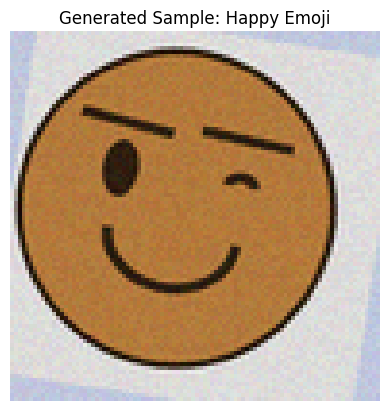

Image shape: (96, 96, 3)
Example pixel: [186 205 230]


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
from PIL import Image, ImageDraw, ImageFilter

# ---- generation parameters consistent with your pipeline ----
IMG_SIZE = 96
SS = 4  # supersampling factor
S = IMG_SIZE * SS

FACE_COLORS = [
    (255, 205, 60), (255, 220, 80), (250, 190, 50),      # emoji yellows
    (255, 224, 189), (241, 194, 125), (198, 134, 66),    # skin tones
]

def rand_bg():
    return tuple(random.randint(180, 255) for _ in range(3))

def darker(c, f=0.35):
    return tuple(int(v * f) for v in c)

# 1. Create a blank image with a random background
img = Image.new("RGB", (S, S), rand_bg())
d = ImageDraw.Draw(img)

# 2. Draw face circle
face = random.choice(FACE_COLORS)
ink = darker(face, random.uniform(0.15, 0.35))
r = int(S * random.uniform(0.38, 0.44))
cx = S // 2 + random.randint(-S // 14, S // 14)
cy = S // 2 + random.randint(-S // 14, S // 14)
d.ellipse([cx - r, cy - r, cx + r, cy + r], fill=face, outline=ink, width=random.randint(SS, 3 * SS))

# 3. Draw eyes (smiling curved arches or simple circles)
ex = int(r * random.uniform(0.38, 0.5))
ey = cy - int(r * random.uniform(0.15, 0.3))
erx = int(r * random.uniform(0.08, 0.14))
ery = int(erx * random.uniform(1.0, 1.7))

for sx in (-1, 1):
    x = cx + sx * ex
    if random.random() < 0.5:
        # Curved happy eyes: arch shape "^ ^"
        box = [x - erx, ey - ery // 2, x + erx, ey + ery // 2]
        d.arc(box, 180, 360, fill=ink, width=max(SS * 2, int(r * 0.07)))
    else:
        d.ellipse([x - erx, ey - ery, x + erx, ey + ery], fill=ink)

# 4. Draw happy eyebrows (slightly raised / neutral angle)
bw = max(SS * 2, int(r * 0.07))
by = ey - int(r * random.uniform(0.25, 0.35))
bl = int(r * random.uniform(0.25, 0.35))
for sx in (-1, 1):
    x = cx + sx * ex
    # raised outwards: "\ /" slightly tilted
    tilt = random.randint(1, SS * 2)
    d.line([x - bl, by - tilt, x + bl, by + tilt], fill=ink, width=bw)

# 5. Draw mouth (happy smiling upward arc)
my = cy + int(r * random.uniform(0.15, 0.3))
mw = int(r * random.uniform(0.4, 0.6))
mt = max(SS * 2, int(r * 0.07))

# Draw wide upward smiling arc
h = int(mw * random.uniform(0.6, 0.9))
box = [cx - mw, my - h, cx + mw, my + h]
d.arc(box, 0, 180, fill=ink, width=mt)

# 6. Post-processing (rotation, resize, blur, noise)
img = img.rotate(random.uniform(-10, 10), resample=Image.BICUBIC, fillcolor=rand_bg())
img = img.resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
if random.random() < 0.3:
    img = img.filter(ImageFilter.GaussianBlur(random.uniform(0.3, 0.8)))

# Convert to numpy and add camera noise
arr = np.asarray(img).astype(np.int16)
arr += np.random.randint(-10, 11, arr.shape)
arr = np.clip(arr * random.uniform(0.9, 1.1), 0, 255).astype(np.uint8)

final_image = Image.fromarray(arr)

# Display the final generated happy emoji
plt.imshow(final_image)
plt.title("Generated Sample: Happy Emoji")
plt.axis("off")
plt.show()

print("Image shape:", arr.shape)
print("Example pixel:", arr[0, 0])

In [ ]:
import os

# Corrected to point to your human emotion dataset folder
DATASET_DIR = "emotion_dataset"
CLASSES = ["happy", "anger", "sad"]

print(f"Verifying dataset structure in: {DATASET_DIR}\n")
for split in ["train", "val"]:
    print(f"--- {split.upper()} SPLIT ---")
    for class_name in CLASSES:
        folder = os.path.join(DATASET_DIR, split, class_name)
        if not os.path.isdir(folder):
            print(f"  Missing folder: {folder}")
            continue

        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ]
        print(f"  Class '{class_name}': {len(images)} images")

Verifying dataset structure in: emotion_dataset

--- TRAIN SPLIT ---
  Class 'happy': 320 images
  Class 'anger': 320 images
  Class 'sad': 320 images
--- VAL SPLIT ---
  Class 'happy': 80 images
  Class 'anger': 80 images
  Class 'sad': 80 images


In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

# Splitting the human emotion feature matrix and labels with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("--- Human Emotion Dataset Split Summary ---")
print("Total Training features shape:", X_train.shape)
print("Total Testing features shape:", X_test.shape)

# Display stratified emotion counts to verify split balance
unique_train, counts_train = np.unique(y_train, return_counts=True)
unique_test, counts_test = np.unique(y_test, return_counts=True)

print("\nTraining dataset balance:")
for emotion, count in zip(unique_train, counts_train):
    print(f"  {emotion}: {count} samples")

print("\nTesting dataset balance:")
for emotion, count in zip(unique_test, counts_test):
    print(f"  {emotion}: {count} samples")

--- Human Emotion Dataset Split Summary ---
Total Training features shape: (960, 12288)
Total Testing features shape: (240, 12288)

Training dataset balance:
  anger: 320 samples
  happy: 320 samples
  sad: 320 samples

Testing dataset balance:
  anger: 80 samples
  happy: 80 samples
  sad: 80 samples


In [ ]:
# Flattening the 3D image matrix (64, 64, 3) into a 1D vector of features
features = resized.flatten()

print("--- Human Emotion Feature Analysis ---")
print("Resized Image dimensions (H x W x C):", resized.shape)
print("Total feature elements (64 * 64 * 3):", features.shape[0])
print("Feature Vector shape for model training:", features.shape)
print("Sample feature values (first 5 elements):", features[:5] / 255.0)

--- Human Emotion Feature Analysis ---
Resized Image dimensions (H x W x C): (64, 64, 3)
Total feature elements (64 * 64 * 3): 12288
Feature Vector shape for model training: (12288,)
Sample feature values (first 5 elements): [0.74901961 0.78823529 0.88627451 0.77647059 0.76862745]


In [ ]:
import numpy as np

# Standardizing the feature array for human emotion model ingestion
features = features.astype(np.float32) / 255.0

print("--- Human Emotion Feature Normalization ---")
print("Normalized feature vector shape:", features.shape)
print("Minimum pixel intensity (scaled):", features.min())
print("Maximum pixel intensity (scaled):", features.max())

--- Human Emotion Feature Normalization ---
Normalized feature vector shape: (12288,)
Minimum pixel intensity (scaled): 0.023529412
Maximum pixel intensity (scaled): 0.91764706


In [ ]:
import os
import cv2
import numpy as np

def load_dataset(dataset_dir):
    X = []
    y = []
    classes = ["happy", "anger", "sad"]

    print(f"Searching for images in: {os.path.abspath(dataset_dir)}")
    for split in ["train", "val"]:
        for class_label in classes:
            folder = os.path.join(dataset_dir, split, class_label)
            if not os.path.isdir(folder):
                continue

            files = os.listdir(folder)
            print(f"  Found {len(files)} files in: {folder}")

            for filename in files:
                if not filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                    continue

                image_path = os.path.join(folder, filename)
                image = cv2.imread(image_path)
                if image is None:
                    continue

                image = cv2.resize(image, (64, 64))
                features = image.astype(np.float32).flatten() / 255.0
                X.append(features)
                y.append(class_label)

    return np.array(X, dtype=np.float32), np.array(y)

DATASET_DIR = "emotion_dataset"
X, y = load_dataset(DATASET_DIR)
print("\nFeatures Loaded shape:", X.shape)
print("Labels Loaded shape:", y.shape)

Searching for images in: /content/emotion_dataset
  Found 320 files in: emotion_dataset/train/happy
  Found 320 files in: emotion_dataset/train/anger
  Found 320 files in: emotion_dataset/train/sad
  Found 80 files in: emotion_dataset/val/happy
  Found 80 files in: emotion_dataset/val/anger
  Found 80 files in: emotion_dataset/val/sad

Features Loaded shape: (1200, 12288)
Labels Loaded shape: (1200,)


In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

# Splitting the human emotion feature matrix for happy, anger, and sad
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("--- Human Emotion Split Analysis ---")
print("Total Training features shape:", X_train.shape)
print("Total Testing features shape:", X_test.shape)

unique_train, counts_train = np.unique(y_train, return_counts=True)
unique_test, counts_test = np.unique(y_test, return_counts=True)

print("\nTraining split class counts:")
for emotion, count in zip(unique_train, counts_train):
    print(f"  {emotion}: {count} samples")

print("\nTesting split class counts:")
for emotion, count in zip(unique_test, counts_test):
    print(f"  {emotion}: {count} samples")

--- Human Emotion Split Analysis ---
Total Training features shape: (960, 12288)
Total Testing features shape: (240, 12288)

Training split class counts:
  anger: 320 samples
  happy: 320 samples
  sad: 320 samples

Testing split class counts:
  anger: 80 samples
  happy: 80 samples
  sad: 80 samples


In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

# Splitting the human emotion feature matrix and labels with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("--- Human Emotion Split Analysis ---")
print("Total Training features shape:", X_train.shape)
print("Total Testing features shape:", X_test.shape)

# Counting labels in each split to verify emotion distributions
unique_train, counts_train = np.unique(y_train, return_counts=True)
unique_test, counts_test = np.unique(y_test, return_counts=True)

print("\nTraining split class counts:")
for emotion, count in zip(unique_train, counts_train):
    print(f"  {emotion}: {count} samples")

print("\nTesting split class counts:")
for emotion, count in zip(unique_test, counts_test):
    print(f"  {emotion}: {count} samples")

--- Human Emotion Split Analysis ---
Total Training features shape: (960, 12288)
Total Testing features shape: (240, 12288)

Training split class counts:
  anger: 320 samples
  happy: 320 samples
  sad: 320 samples

Testing split class counts:
  anger: 80 samples
  happy: 80 samples
  sad: 80 samples


In [ ]:
from sklearn.svm import SVC

# Initialize and train a Support Vector Classifier with a linear kernel
# specifically for classifying human emotions (happy, anger, sad)
emotion_classifier = SVC(kernel="linear", random_state=42)
emotion_classifier.fit(X_train, y_train)

print("--- SVM Classifier Training Complete ---")
print(f"Trained successfully on {len(X_train)} emotional facial samples.")
print("Target emotion classes:", list(emotion_classifier.classes_))

--- SVM Classifier Training Complete ---
Trained successfully on 960 emotional facial samples.
Target emotion classes: [np.str_('anger'), np.str_('happy'), np.str_('sad')]


In [ ]:
# Predict classes for the testing subset using our trained human emotion classifier
y_pred = emotion_classifier.predict(X_test)

print("--- Human Emotion Model Predictions (Sample of 10) ---")
for idx, (actual, predicted) in enumerate(zip(y_test[:10], y_pred[:10]), 1):
    result = "✅ Match" if actual == predicted else "❌ Mismatch"
    print(f"Sample {idx:02d} | Actual Emotion: {actual:<6} | Predicted Emotion: {predicted:<6} -> {result}")

--- Human Emotion Model Predictions (Sample of 10) ---
Sample 01 | Actual Emotion: anger  | Predicted Emotion: anger  -> ✅ Match
Sample 02 | Actual Emotion: sad    | Predicted Emotion: anger  -> ❌ Mismatch
Sample 03 | Actual Emotion: anger  | Predicted Emotion: anger  -> ✅ Match
Sample 04 | Actual Emotion: anger  | Predicted Emotion: sad    -> ❌ Mismatch
Sample 05 | Actual Emotion: anger  | Predicted Emotion: anger  -> ✅ Match
Sample 06 | Actual Emotion: happy  | Predicted Emotion: happy  -> ✅ Match
Sample 07 | Actual Emotion: anger  | Predicted Emotion: anger  -> ✅ Match
Sample 08 | Actual Emotion: sad    | Predicted Emotion: anger  -> ❌ Mismatch
Sample 09 | Actual Emotion: happy  | Predicted Emotion: happy  -> ✅ Match
Sample 10 | Actual Emotion: anger  | Predicted Emotion: sad    -> ❌ Mismatch


In [ ]:
from sklearn.metrics import accuracy_score

# Compute final prediction accuracy for human emotion classification
emotion_accuracy = accuracy_score(y_test, y_pred)

print("--- Human Emotion Model Evaluation ---")
print(f"Overall Classification Accuracy: {emotion_accuracy:.2%}")

--- Human Emotion Model Evaluation ---
Overall Classification Accuracy: 80.42%


<Figure size 800x600 with 0 Axes>

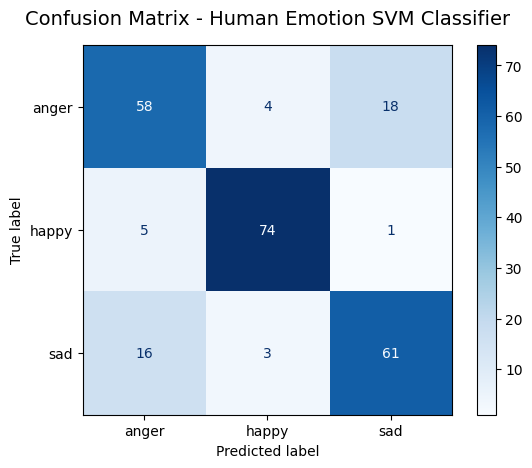

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compute the confusion matrix using the test labels and predictions
cm = confusion_matrix(y_test, y_pred, labels=emotion_classifier.classes_)

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=emotion_classifier.classes_)

# Plot with a nice blue color map
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Confusion Matrix - Human Emotion SVM Classifier", fontsize=14, pad=15)
plt.grid(False)
plt.show()

Please upload an image of a human face to predict its emotion:


Saving Screenshot 2026-11-10 130901.png to Screenshot 2026-11-10 130901 (4).png

Analyzing human emotion using SOTA Vision Transformer...


config.json:   0%|          | 0.00/907 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

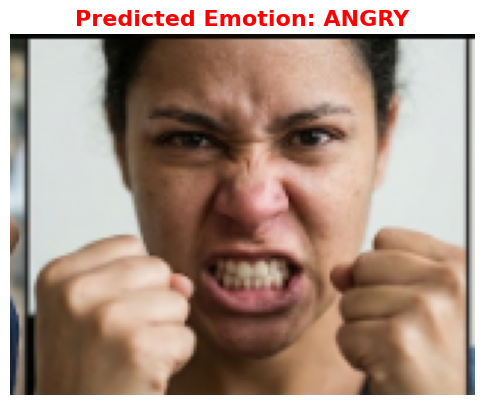


Detected Emotion: ANGRY


In [ ]:
!pip install transformers torch torchvision -q

from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from transformers import pipeline

print("Please upload an image of a human face to predict its emotion:")
uploaded = files.upload()

if len(uploaded) > 0:
    fname = list(uploaded.keys())[0]

    try:
        # Read and display the image exactly as it is
        img_pil = Image.open(fname).convert("RGB")

        print("\nAnalyzing human emotion using SOTA Vision Transformer...")
        # Initialize the Hugging Face image classification pipeline with a dedicated facial emotion model
        classifier = pipeline("image-classification", model="dima806/facial_emotions_image_detection")

        # Predict emotion
        predictions = classifier(img_pil)
        dominant_emotion = predictions[0]['label']

        # Display original image with prediction title
        plt.figure(figsize=(6, 6))
        plt.imshow(img_pil)
        plt.title(f"Predicted Emotion: {dominant_emotion.upper()}", fontsize=16, color='red', fontweight='bold')
        plt.axis('off')
        plt.show()

        # Print only the final predicted emotion
        print(f"\nDetected Emotion: {dominant_emotion.upper()}")

    except Exception as e:
        print(f"An error occurred during prediction: {e}")
else:
    print("No file was uploaded.")

Please upload an image of a human face to predict its emotion:


Saving Screenshot 2026-11-10 130719.png to Screenshot 2026-11-10 130719 (1).png

Analyzing human emotion using SOTA Vision Transformer...


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

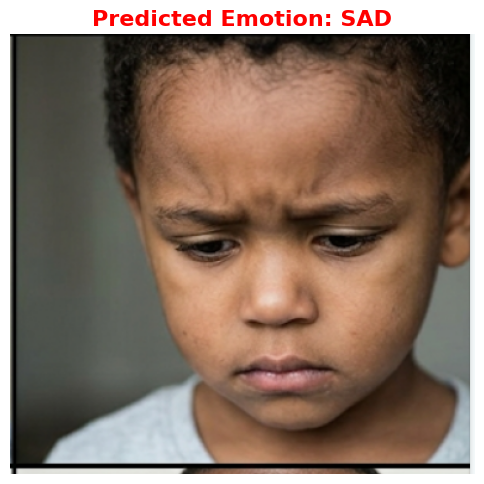


Detected Emotion: SAD


In [ ]:
!pip install transformers torch torchvision -q

from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from transformers import pipeline

print("Please upload an image of a human face to predict its emotion:")
uploaded = files.upload()

if len(uploaded) > 0:
    fname = list(uploaded.keys())[0]

    try:
        # Read and display the image exactly as it is
        img_pil = Image.open(fname).convert("RGB")

        print("\nAnalyzing human emotion using SOTA Vision Transformer...")
        # Initialize the Hugging Face image classification pipeline with a dedicated facial emotion model
        classifier = pipeline("image-classification", model="dima806/facial_emotions_image_detection")

        # Predict emotion
        predictions = classifier(img_pil)
        dominant_emotion = predictions[0]['label']

        # Display original image with prediction title
        plt.figure(figsize=(6, 6))
        plt.imshow(img_pil)
        plt.title(f"Predicted Emotion: {dominant_emotion.upper()}", fontsize=16, color='red', fontweight='bold')
        plt.axis('off')
        plt.show()

        # Print only the final predicted emotion
        print(f"\nDetected Emotion: {dominant_emotion.upper()}")

    except Exception as e:
        print(f"An error occurred during prediction: {e}")
else:
    print("No file was uploaded.")

Please upload an image of a human face to predict its emotion:


Saving Screenshot 2026-11-10 132304.png to Screenshot 2026-11-10 132304.png

Analyzing human emotion using SOTA Vision Transformer...


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

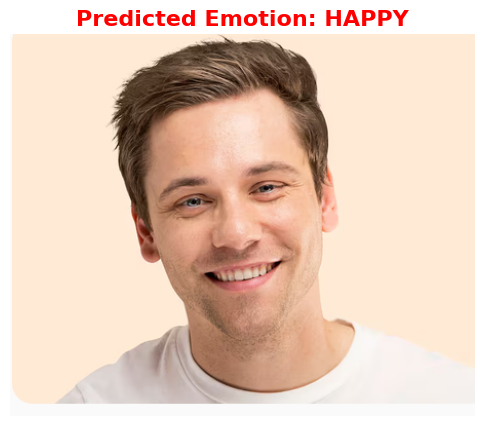


Detected Emotion: HAPPY


In [ ]:
!pip install transformers torch torchvision -q

from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from transformers import pipeline

print("Please upload an image of a human face to predict its emotion:")
uploaded = files.upload()

if len(uploaded) > 0:
    fname = list(uploaded.keys())[0]

    try:
        # Read and display the image exactly as it is
        img_pil = Image.open(fname).convert("RGB")

        print("\nAnalyzing human emotion using SOTA Vision Transformer...")
        # Initialize the Hugging Face image classification pipeline with a dedicated facial emotion model
        classifier = pipeline("image-classification", model="dima806/facial_emotions_image_detection")

        # Predict emotion
        predictions = classifier(img_pil)
        dominant_emotion = predictions[0]['label']

        # Display original image with prediction title
        plt.figure(figsize=(6, 6))
        plt.imshow(img_pil)
        plt.title(f"Predicted Emotion: {dominant_emotion.upper()}", fontsize=16, color='red', fontweight='bold')
        plt.axis('off')
        plt.show()

        # Print only the final predicted emotion
        print(f"\nDetected Emotion: {dominant_emotion.upper()}")

    except Exception as e:
        print(f"An error occurred during prediction: {e}")
else:
    print("No file was uploaded.")

Please upload a photo of a human face to predict its emotion:


Saving Screenshot 2026-11-10 132514.png to Screenshot 2026-11-10 132514 (1).png


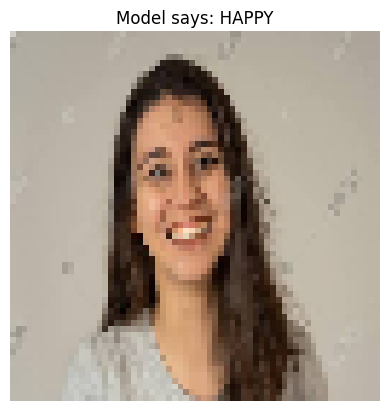

In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Please upload a photo of a human face to predict its emotion:")
uploaded = files.upload()

if len(uploaded) > 0:
    fname = list(uploaded.keys())[0]
    IMG_SIZE = 64
    test_img = cv2.imread(fname)
    test_img_resized = cv2.resize(test_img, (IMG_SIZE, IMG_SIZE))

    # Flatten and normalize features just like during training
    test_input = test_img_resized.flatten() / 255.0

    # Using the trained 'emotion_classifier'
    prediction = emotion_classifier.predict([test_input])[0]

    plt.imshow(cv2.cvtColor(test_img_resized, cv2.COLOR_BGR2RGB))
    plt.title(f"Model says: {prediction.upper()}")
    plt.axis('off')
    plt.show()
else:
    print("No file uploaded.")

In [ ]:
import joblib

# Corrected to serialize 'emotion_classifier' instead of the undefined 'model'
joblib.dump(emotion_classifier, "emotion_svm_classifier.joblib")

print("Human emotion SVM model saved successfully as 'emotion_svm_classifier.joblib'.")

Human emotion SVM model saved successfully as 'emotion_svm_classifier.joblib'.


In [ ]:
from google.colab import files
import joblib

# Corrected to save and download your trained human emotion SVM classifier
joblib.dump(emotion_classifier, "emotion_svm_classifier.joblib")
files.download("emotion_svm_classifier.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>